In [1]:
import ksets_cpp as cksets
from importlib import reload
import pathlib
import numpy as np
import ksets_cpp.uef_clustering.ksets as ksets
np.__version__
cksets = reload(cksets)
ksets = reload(ksets)

In [2]:
datadir = pathlib.Path("..") / "data" / "artificial"

In [3]:
list(datadir.glob("*1200_100_16_5_1*"))

[PosixPath('../data/artificial/data_1200_100_16_5_1.txt'),
 PosixPath('../data/artificial/representative_1200_100_16_5_1.txt'),
 PosixPath('../data/artificial/gt_labels_1200_100_16_5_1.txt')]

In [19]:
data_f, rep, gt_labels = list(datadir.glob("*1200_100_16_5_1*"))

In [20]:
manual_entry = False
if manual_entry:
    data = [
        ["A", "E", "B", "C", "F"],
        ["D", "G", "A", "B"],
        ["I", "A", "C", "J", "B"],
        ["A", "H", "C", "B"],
        ["A", "E", "F", "C", "B"],
        ["D", "G", "A", "B"]]
    data = np.array([np.array(x) for x in data], dtype="object")
else:
    data = cksets.read_file(data_f)

data

array([array(['L94', 'K31', 'H32', 'H48', 'C02', 'D59'], dtype='<U3'),
       array(['J45', 'B27', 'Q16', 'M51', 'S60'], dtype='<U3'),
       array(['A02', 'S89', 'G57', 'F92', 'R92', 'H48'], dtype='<U3'),
       ...,
       array(['F44', 'A02', 'B18', 'I79', 'B27', 'S20'], dtype='<U3'),
       array(['F92', 'M93', 'Q16', 'G57', 'T27', 'H50', 'N12', 'F22', 'C15',
              'H32', 'L43'], dtype='<U3')                                   ,
       array(['G37', 'J45', 'A02', 'H32'], dtype='<U3')],
      shape=(1200,), dtype=object)

In [6]:
import timeit
K = 256 # Number of clusters
MAX_HIST_LENGTH = 0 #20 # if zero no limitation
RS_ITER = 300 # number of iterations for kswaps
#rand_seed =None
rand_seed = 33
np.random.seed(rand_seed)
initial_hist = cksets.build_initial_histograms(data, K)
initial_hist

[{np.str_('A70'): np.int64(1),
  np.str_('H32'): np.int64(1),
  np.str_('J45'): np.int64(1),
  np.str_('N30'): np.int64(1),
  np.str_('O28'): np.int64(1),
  np.str_('Q98'): np.int64(1)},
 {np.str_('F92'): np.int64(1),
  np.str_('G37'): np.int64(1),
  np.str_('G57'): np.int64(1),
  np.str_('H50'): np.int64(1),
  np.str_('M93'): np.int64(1),
  np.str_('N94'): np.int64(1),
  np.str_('Q98'): np.int64(1),
  np.str_('T27'): np.int64(1)},
 {np.str_('B18'): np.int64(1),
  np.str_('B43'): np.int64(1),
  np.str_('C02'): np.int64(1),
  np.str_('F22'): np.int64(1),
  np.str_('G21'): np.int64(1),
  np.str_('H26'): np.int64(1),
  np.str_('I45'): np.int64(1),
  np.str_('L71'): np.int64(1),
  np.str_('M93'): np.int64(1),
  np.str_('N28'): np.int64(1),
  np.str_('Q80'): np.int64(1),
  np.str_('Q98'): np.int64(1),
  np.str_('R05'): np.int64(1),
  np.str_('R23'): np.int64(1),
  np.str_('R54'): np.int64(1),
  np.str_('S80'): np.int64(1),
  np.str_('T20'): np.int64(1),
  np.str_('V49'): np.int64(1)},
 {np.

In [7]:
from memory_profiler import memory_usage
import pandas as pd
#mem_usage = pd.DataFrame({"mem_usage": memory_usage((ksets.cluster,(data, K, MAX_HIST_LENGTH, None, 50)))})
#mem_usage.plot()

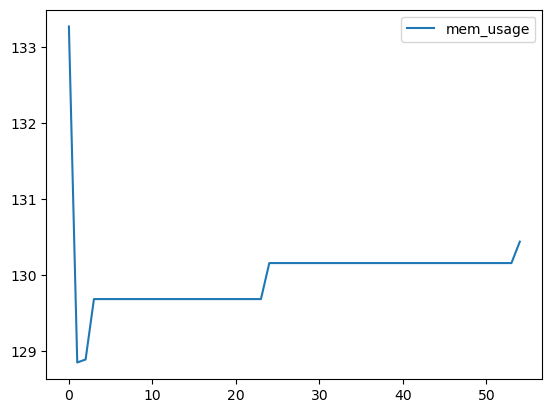

In [8]:
mem_usage = pd.DataFrame({"mem_usage": memory_usage((cksets.cluster,(data, K, MAX_HIST_LENGTH, None, 50), {"hist_rebuild":"full"}), interval=0.01)})
ax = mem_usage.plot()
ax.ticklabel_format(useOffset=False)

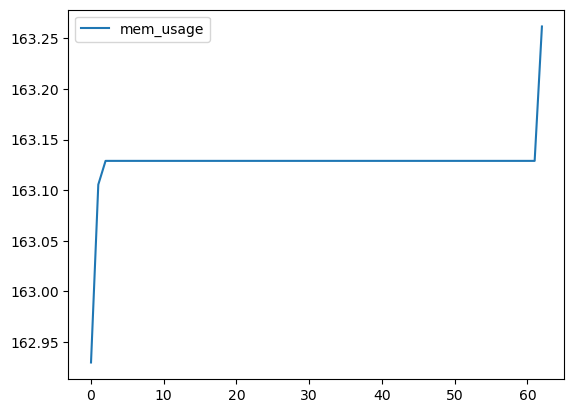

In [9]:
mem_usage = pd.DataFrame({"mem_usage": memory_usage((cksets.cluster,(data, K, MAX_HIST_LENGTH, None, 50), {"hist_rebuild":"memorize"}), interval=0.01)})
ax2 = mem_usage.plot()
ax2.ticklabel_format(useOffset=False)

In [10]:
ksets.LOG_ENABLE = False
ksets.LOG_ITERCOUNT = 1
print(timeit.timeit('labels, khist, sdh = cksets.cluster(data, K, MAX_HIST_LENGTH, None, 50, hist_rebuild="full")', number=10 ,globals=globals()))

5.250649359077215


In [11]:
#print(timeit.timeit('labels, khist, sdh = cksets.cluster(data, K, MAX_HIST_LENGTH, None, 50, hist_rebuild="memorize")', number=10,globals=globals()))

In [12]:
#print(timeit.timeit('labels, khist, sdh = ksets.cluster(data, K, MAX_HIST_LENGTH, None, 50)', number=10,globals=globals()))

In [13]:
clabels, ckhist, csdh = cksets.cluster(data, K, MAX_HIST_LENGTH, initial_hist,50)

In [14]:
labels, khist, sdh = ksets.cluster(data, K, MAX_HIST_LENGTH, initial_hist, 50)

In [15]:

list(f"{x},{y}" for x,y in zip(clabels,labels) if x!=y)

['39,240',
 '158,78',
 '38,122',
 '241,192',
 '179,189',
 '179,219',
 '72,24',
 '78,24',
 '187,141',
 '219,179',
 '159,65',
 '138,122',
 '154,122',
 '34,192',
 '38,122',
 '208,141',
 '198,147',
 '225,206',
 '44,122',
 '55,147',
 '11,60',
 '190,212',
 '100,225',
 '202,240',
 '24,78',
 '127,212',
 '190,212',
 '55,198',
 '81,9',
 '179,219',
 '100,206',
 '241,192',
 '127,212',
 '192,146',
 '240,39',
 '143,141',
 '113,54',
 '30,122',
 '219,179',
 '198,55',
 '44,122',
 '58,120',
 '205,57',
 '198,55',
 '80,78',
 '9,120',
 '55,147',
 '93,78',
 '147,26',
 '13,24',
 '113,54',
 '172,120',
 '192,146',
 '177,60',
 '236,157',
 '46,141',
 '190,212',
 '13,24',
 '179,48',
 '154,122',
 '3,182',
 '250,240',
 '78,24',
 '240,39',
 '68,65',
 '76,184',
 '198,193',
 '98,212',
 '178,122',
 '100,206',
 '4,122',
 '238,101',
 '108,184',
 '159,65',
 '113,54',
 '196,11',
 '98,212',
 '179,219',
 '205,184',
 '62,122',
 '59,1',
 '1,59',
 '219,179',
 '39,182',
 '154,122',
 '78,80',
 '198,166',
 '211,54',
 '141,171',
 '

In [16]:
khist

[{np.str_('A70'): np.int64(1),
  np.str_('H32'): np.int64(1),
  np.str_('J45'): np.int64(1),
  np.str_('N30'): np.int64(1),
  np.str_('O28'): np.int64(1),
  np.str_('Q98'): np.int64(1)},
 {np.str_('F92'): np.int64(1),
  np.str_('G37'): np.int64(1),
  np.str_('G57'): np.int64(1),
  np.str_('H50'): np.int64(1),
  np.str_('M93'): np.int64(1),
  np.str_('N94'): np.int64(1),
  np.str_('Q98'): np.int64(1),
  np.str_('T27'): np.int64(1)},
 {np.str_('B18'): np.int64(2),
  np.str_('B43'): np.int64(4),
  np.str_('C02'): np.int64(2),
  np.str_('C85'): np.int64(1),
  np.str_('D22'): np.int64(1),
  np.str_('D37'): np.int64(1),
  np.str_('D59'): np.int64(1),
  np.str_('E44'): np.int64(1),
  np.str_('F09'): np.int64(2),
  np.str_('F22'): np.int64(1),
  np.str_('F78'): np.int64(1),
  np.str_('G21'): np.int64(1),
  np.str_('G57'): np.int64(1),
  np.str_('G72'): np.int64(1),
  np.str_('H26'): np.int64(1),
  np.str_('H52'): np.int64(1),
  np.str_('I45'): np.int64(3),
  np.str_('I65'): np.int64(1),
  np.s

In [17]:
list(f"{x},{y}" for x,y in zip(sdh,csdh) if x!=y)

['11.51466030470532,11.151023941068953',
 '0.6181818181818182,0.9818181818181818']